# Signature lead-lag networks

This study reproduces a published crypto lead-lag implementation and tests a corrected spectral variant. The main result is a **1.41 historical gross Sharpe** for the global portfolio, on a retrospective 57-asset universe. It is a gross research result under idealized same-close execution, not a live or independent out-of-sample track record.

The source is [ARahimiQuant/lead-lag-portfolios](https://github.com/ARahimiQuant/lead-lag-portfolios), pinned in `config.json`. Its MIT notice is retained. Raw prices download from that revision and are verified by SHA-256.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "config.json").exists():
    ROOT = ROOT.parent
ARTIFACTS = ROOT / "artifacts"
def read(name):
    return pd.read_csv(ARTIFACTS / (name + ".csv"))
pd.options.display.max_columns = 12
config = json.loads((ROOT / "config.json").read_text())
run = json.loads((ARTIFACTS / "run.json").read_text())
print("Assets:", run["assets"], "| raw price rows:", run["price_rows"])
print("Input SHA-256:", run["price_sha256"])
print("Window:", config["window"], "days | Leaders/followers:", config["selection_fraction"])
print("Missing marks carried forward in raw panel:", run["valuation_gaps"])

Assets: 57 | raw price rows: 2272
Input SHA-256: e919b8d5c3cd712f1ff006aec5c50cc52fb4614b87041c2788f5285215da5b0b
Window: 30 days | Leaders/followers: 0.2
Missing marks carried forward in raw panel: 48


## Reproduce before changing the model

The original global-portfolio result is reproduced at 1.43 under the source's CAGR-based ratio, close to its reported 1.42. A conventional arithmetic-return Sharpe using the source's 2% rate is 1.32. Those are different statistics; they should not share an unlabeled headline.

The replay required a pandas positional-indexing update and an exact NumPy replacement for the level-two piecewise-linear signature. The source's global ranking and return logic were retained for that comparison.

In [2]:
display(read("upstream_reproduction").round(4))
audit = json.loads((ARTIFACTS / "upstream_audit.json").read_text())
print("Pinned revision:", audit["revision"])
print("Compatibility changes:", audit["compatibility_changes"])

,mode,days,first,last,total_return,cagr,volatility,upstream_sharpe,conventional_sharpe,max_drawdown
0,upstream_gp,1536,2019-08-23 00:00:00,2023-11-05 00:00:00,3.2515,0.4108,0.2729,1.4319,1.3232,-0.2322


Pinned revision: e02c2fbd62b8d823bbb605b6234a88a565fafee6
Compatibility changes: ['pandas positional indexing via iloc', 'exact piecewise-linear level-2 signature in NumPy', 'vectorized pairwise Levy areas']


## From paths to a directed network

Let $z_t$ be the standardized daily return vector in the trailing 30-day window. The antisymmetric level-two area is

$$A=\frac12\sum_t [(z_t-z_0)\,\Delta z_t^\top-\Delta z_t\,(z_t-z_0)^\top].$$

One matrix multiplication pair computes all pairwise areas. This matches an independent segment-by-segment signature recursion in the tests. Positive and negative row averages rank leaders and followers. The sign of the leaders' latest return chooses which side of the follower-minus-universe portfolio to hold.

The global strategy's gross exposure is generally about 1.6, because the follower and universe baskets overlap. Weights are dollar neutral; that does not imply zero market beta. There is no volatility targeting or parameter search here.

## Spectral normalization

For real antisymmetric scores $A$, $iA$ is Hermitian. Scaling by positive absolute degrees, $D_{jj}=\sum_k|A_{jk}|$, preserves that property. The original implementation instead uses signed complex row sums. The first observed normalized matrix has the defect shown below, so its use with a Hermitian eigensolver is not justified by that symmetry assumption.

This implementation uses absolute degrees and a dense Hermitian eigensolver. Real and imaginary eigenvector coordinates feed seeded K-means, and the historical-window silhouette score selects 3–10 clusters. The corrected clustered result is reported even though it is weaker; the advertised 1.95 is not claimed as reproduced.

Original normalization max |H-H*|: 1.676689298966408


,mode,days,sharpe,sharpe_rf_2pct,max_drawdown,mean_daily_turnover
0,clustered,1538,0.2232,0.150,-0.4095,2.0626
8,global,1538,1.4123,1.339,-0.2321,1.9017


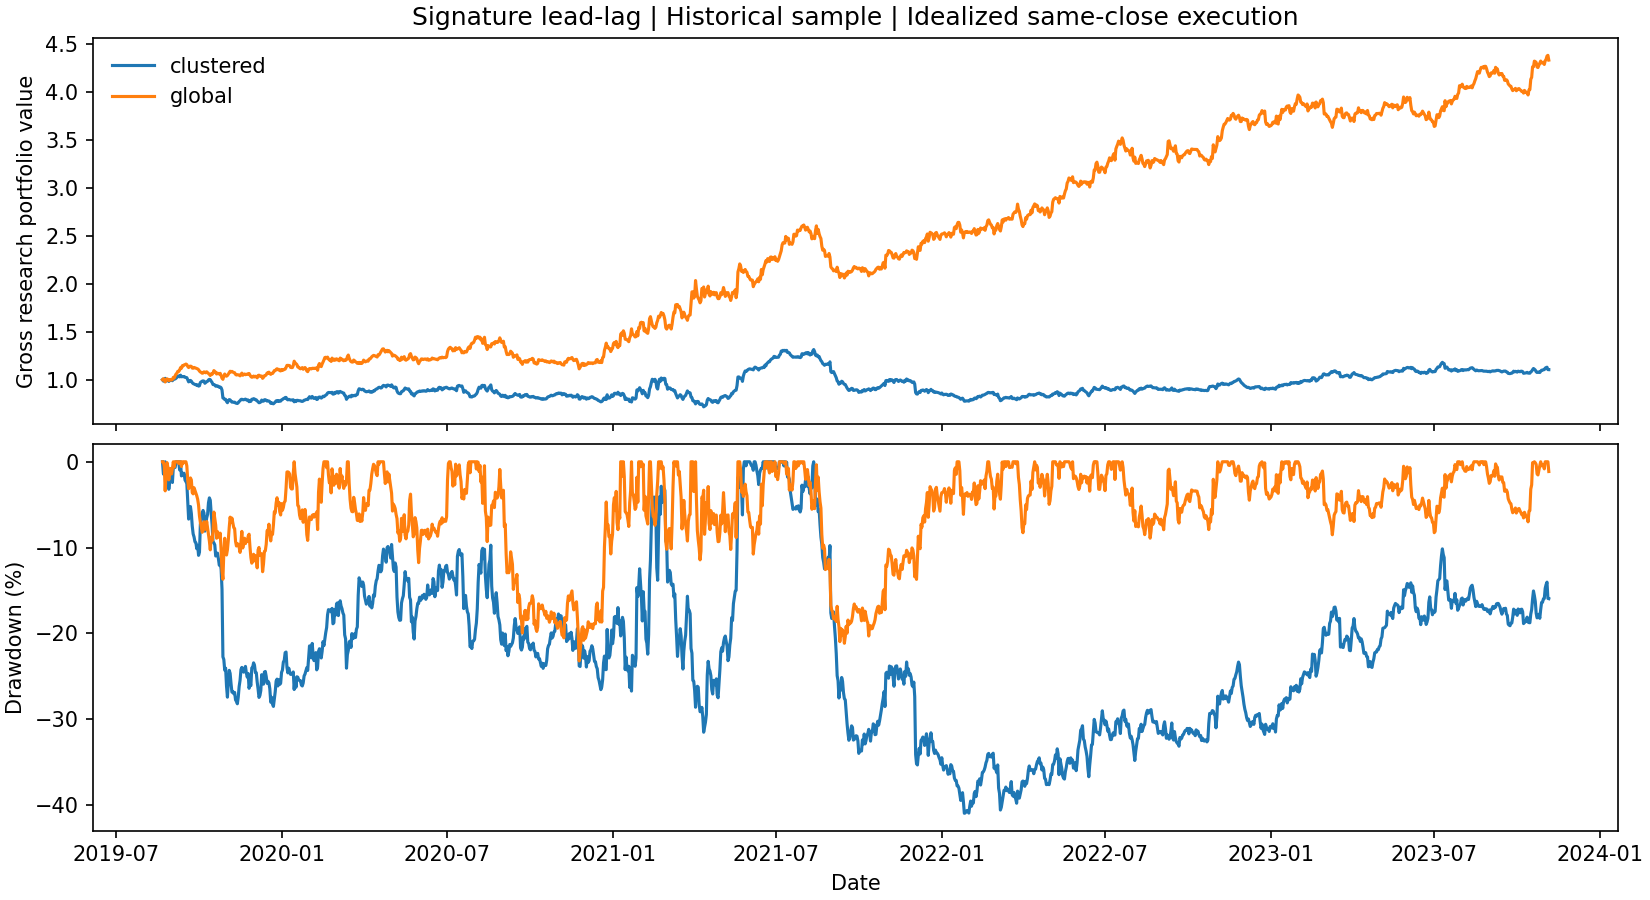

In [3]:
print("Original normalization max |H-H*|:", audit["normalized_matrix_hermitian_defect"])
scores = read("scores")
display(scores.query("cost_bps == 0 and extra_delay == 0")[["mode", "days", "sharpe", "sharpe_rf_2pct", "max_drawdown", "mean_daily_turnover"]].round(4))
display(Image(filename=str(ARTIFACTS / "performance.png")))

## Fees and timing

The zero-delay convention forms the signal and trades at the same closing price. It is an idealization. One additional day means that a signal observed at close t executes at close t+1 and first earns the following interval's return.

The grid below charges each traded dollar at 0, 5, 10 or 20 bps, with initial entry and final liquidation included. Post-fee target notionals solve the fee equation. Funding, short borrow fees and borrow availability remain excluded. Missing prices are carried forward for valuation, which is not an executable-fill assumption.

At 5 bps, global Sharpe is only 0.14. A full extra day of delay takes gross Sharpe below zero. These are material limits of the strategy.

In [4]:
display(scores[["mode", "extra_delay", "cost_bps", "sharpe", "max_drawdown"]].round(4))

,mode,extra_delay,cost_bps,sharpe,max_drawdown
0,clustered,0,0,0.2232,-0.4095
1,clustered,0,5,-1.1586,-0.7828
2,clustered,0,10,-2.5437,-0.9542
3,clustered,0,20,-5.3046,-0.9981
4,clustered,1,0,-0.3850,-0.6067
5,clustered,1,5,-1.8872,-0.8965
6,clustered,1,10,-3.3829,-0.9771
7,clustered,1,20,-6.3309,-0.9990
8,global,0,0,1.4123,-0.2321
9,global,0,5,0.1379,-0.3723


## Historical stability and uncertainty

The following are descriptive subperiods of the source's existing historical sample. They are not fresh holdouts. Both global subperiods are positive before costs, while the corrected clustered variant is substantially less stable.

The gross Sharpe intervals resample common 30-day blocks across both portfolios, with 2,000 repetitions. They do not correct for the source's strategy-selection history or retrospective universe construction.

In [5]:
display(read("subperiods")[["mode", "period", "days", "sharpe", "max_drawdown"]].round(4))
display(read("uncertainty").round(4))

,mode,period,days,sharpe,max_drawdown
0,clustered,2019-2021,864,-0.0441,-0.3532
1,clustered,2022-2023,674,0.8717,-0.1099
2,global,2019-2021,864,1.3527,-0.2321
3,global,2022-2023,674,1.7164,-0.0890


,mode,lower_95,upper_95,block_days,repetitions
0,clustered,-0.8333,1.2997,30,2000
1,global,0.6297,2.1623,30,2000


The result supports a historical predictive relationship under the modeled daily timing convention. It does not demonstrate deployable profit after costs or execution latency. The main implementation contributions are vectorized signatures, an explicitly Hermitian spectral construction, an observable hedge universe and tested portfolio accounting.

The repository includes daily returns, target weights, source/data fingerprints and nine numerical tests. To rebuild everything, run `python -m leadlag.research`. The first clustered-target run takes several minutes.

References: [Bennett, Cucuringu and Reinert](https://arxiv.org/abs/2201.08283); [Chevyrev and Kormilitzin](https://arxiv.org/abs/1603.03788).